In [40]:
import sys

import os
import re
import click
import tqdm
import pickle
import numpy as np
import torch
import PIL.Image
import dnnlib
from torch_utils import distributed as dist
from PIL import Image
from tqdm import tqdm
from matplotlib import pyplot as plt
import torch.nn.functional as F

from project_utils.paths import PROJECT_ROOT, CONFIG_DIR, DATA_DIR
from pou import gen_weight_grid, f2p, p2f

In [41]:
def edm_sampler(
    net, latents, conditions=None, class_labels=None, randn_like=torch.randn_like,
    num_steps=18, sigma_min=0.002, sigma_max=80, rho=7,
    S_churn=0, S_min=0, S_max=float('inf'), S_noise=1,
):
    # Adjust noise levels based on what's supported by the network.
    sigma_min = max(sigma_min, net.sigma_min)
    sigma_max = min(sigma_max, net.sigma_max)

    # Time step discretization.
    step_indices = torch.arange(num_steps, dtype=torch.float64, device=latents.device)
    t_steps = (sigma_max ** (1 / rho) + step_indices / (num_steps - 1) * (sigma_min ** (1 / rho) - sigma_max ** (1 / rho))) ** rho
    t_steps = torch.cat([net.round_sigma(t_steps), torch.zeros_like(t_steps[:1])]) # t_N = 0

    # Main sampling loop.
    x_next = latents.to(torch.float64) * t_steps[0]
    for i, (t_cur, t_next) in enumerate(zip(t_steps[:-1], t_steps[1:])): # 0, ..., N-1
        x_cur = x_next

        # Increase noise temporarily.
        gamma = min(S_churn / num_steps, np.sqrt(2) - 1) if S_min <= t_cur <= S_max else 0
        t_hat = net.round_sigma(t_cur + gamma * t_cur)
        x_hat = x_cur + (t_hat ** 2 - t_cur ** 2).sqrt() * S_noise * randn_like(x_cur)

        # Euler step.
        denoised = net(x_hat, t_hat, conditions, class_labels).to(torch.float64)
        
        d_cur = (x_hat - denoised) / t_hat
        x_next = x_hat + (t_next - t_hat) * d_cur

        # Apply 2nd order correction.
        if i < num_steps - 1:
            denoised = net(x_next, t_next, conditions, class_labels).to(torch.float64)
            d_prime = (x_next - denoised) / t_next
            x_next = x_hat + (t_next - t_hat) * (0.5 * d_cur + 0.5 * d_prime)

    return x_next




In [44]:
# device 
device=torch.device('cuda:0')


# Load network.
# network_pkl = '/home/zez0002/cond-diff-pou/outputs/00003-sqg_patch_c0-medium-gpus1-batch256-fp32/network-snapshot-002000.pkl' # medium


# network_pkl = '/home/zez0002/cond-diff-pou/outputs/00006-sqg_patch_c0-ddpmpp-gpus1-batch200-fp32/network-snapshot-002000.pkl' # ddpmpp

# network_pkl = '/home/zez0002/cond-diff-pou/outputs/00007-sqg_patch_c0-medium-gpus1-batch256-fp32/network-snapshot-002000.pkl' # new 
# network_pkl = '/home/zez0002/cond-diff-pou/outputs/00007-sqg_patch_c0-medium-gpus1-batch256-fp32/network-snapshot-001024.pkl' # new 
# network_pkl = '/home/zez0002/cond-diff-pou/outputs/00007-sqg_patch_c0-medium-gpus1-batch256-fp32/network-snapshot-000512.pkl' # new 
# network_pkl = '/home/zez0002/cond-diff-pou/outputs/00008-sqg_patch_c0-medium-gpus1-batch256-fp32/network-snapshot-000500.pkl' # new
network_pkl = '/home/zez0002/cond-diff-pou/outputs/00009-sqg_patch_c0-medium-gpus1-batch256-fp32/network-snapshot-000500.pkl'



# from direct EDM training 
# network_pkl = '/home/zez0002/diff-turb/training-32-corp/00001-fields_32_corp-uncond-ddpmpp-edm-gpus1-batch200-fp32/network-snapshot-001000.pkl'
# network_pkl = '/home/zez0002/diff-turb/training-32-corp/00001-fields_32_corp-uncond-ddpmpp-edm-gpus1-batch200-fp32/network-snapshot-000500.pkl'
# network_pkl = '/home/zez0002/diff-turb/training-32-corp/00002-fields_32_corp-uncond-mid-edm-gpus1-batch256-fp32/network-snapshot-001000.pkl' # mid model
# network_pkl = '/home/zez0002/diff-turb/training-32-corp/00005-fields_32_corp-uncond-mid-edm-gpus1-batch256-fp32/network-snapshot-001000.pkl'


print(f'Loading network from "{network_pkl}"...')
with dnnlib.util.open_url(network_pkl, verbose=True) as f:
    net_32_patch = pickle.load(f)['ema'].to(device)
    
try:
    print('condition channels: ',net_32_patch.img_cond_channels)
except:
    print('no condition channels')

Loading network from "/home/zez0002/cond-diff-pou/outputs/00009-sqg_patch_c0-medium-gpus1-batch256-fp32/network-snapshot-000500.pkl"...
condition channels:  0


In [45]:
model1 = net_32_patch
total_params = sum(p.numel() for p in model1.parameters())
print('my')
print("Total parameters:", total_params)

my
Total parameters: 26492033


In [43]:
model2 = net_32_patch
total_params = sum(p.numel() for p in model2.parameters())
print('edm')
print("Total parameters:", total_params)


edm
Total parameters: 26492033


torch.Size([9, 1, 32, 32])


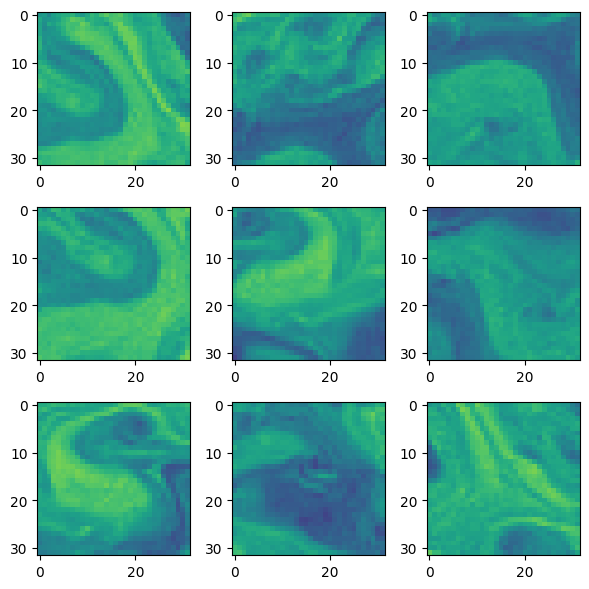

In [46]:
# generate hi res patch
batch_size = 9
latents = torch.randn([batch_size, 1, 32, 32], device=device)
samples = edm_sampler(net_32_patch, latents)
print(samples.shape)

# plot grid 
x = samples[:,0,:,:].cpu().numpy()  # convert to numpy if needed
grid_size = 3
fig, axes = plt.subplots(grid_size, grid_size, figsize=(6, 6))
# fig.tight_layout(pad=1.0)
for i in range(3):
    for j in range(3):
        axes[i, j].imshow(x[i*3 + j], cmap='viridis', vmin=-1.0, vmax=1.0)
        # axes[i, j].axis('off')
plt.tight_layout()
plt.show()

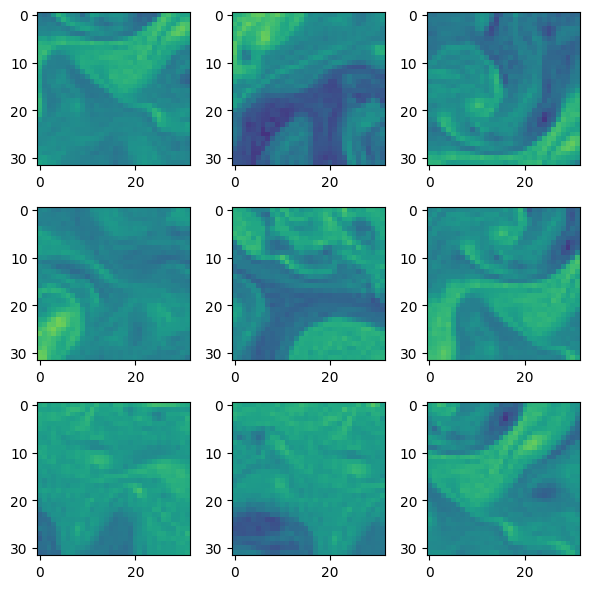

In [36]:
# load some training samples 
# show SQG orignal fields
data_snaps_dir = os.path.join(DATA_DIR, "SQG","SQG_v_0_patch_32_c_2","snaps" ) # root SQG data dir
# 
fig, axes = plt.subplots(grid_size, grid_size, figsize=(6, 6))
for i in range(3):
    for j in range(3):
        data_path = os.path.join(data_snaps_dir, f"sample_{i*3 + j + 123:06d}.pt")
        data = torch.load(data_path)
        x = data['targets']
        axes[i, j].imshow(x[0], cmap='viridis', vmin=-1.0, vmax=1.0)
        # axes[i, j].axis('off')
plt.tight_layout()
plt.show()

In [47]:
def edm_sampler_pou(
    weight_grid_2d, net, latents, conditions=None, 
    class_labels=None, randn_like=torch.randn_like,
    num_steps=18, sigma_min=0.002, sigma_max=80, rho=7,
    S_churn=0, S_min=0, S_max=float('inf'), S_noise=1,
):
    # Adjust noise levels based on what's supported by the network.
    sigma_min = max(sigma_min, net.sigma_min)
    sigma_max = min(sigma_max, net.sigma_max)

    # Time step discretization.
    step_indices = torch.arange(num_steps, dtype=torch.float64, device=latents.device)
    t_steps = (sigma_max ** (1 / rho) + step_indices / (num_steps - 1) * (sigma_min ** (1 / rho) - sigma_max ** (1 / rho))) ** rho
    t_steps = torch.cat([net.round_sigma(t_steps), torch.zeros_like(t_steps[:1])]) # t_N = 0

    # condition (BCHW)
    patch_cond = f2p(conditions) if conditions is not None else None
    weight_grid_flat = weight_grid_2d.view(-1, 1, weight_grid_2d.shape[2], weight_grid_2d.shape[3]).to(latents.device)

    # Main sampling loop.
    x_next = latents.to(torch.float64) * t_steps[0]
    for i, (t_cur, t_next) in enumerate(zip(t_steps[:-1], t_steps[1:])): # 0, ..., N-1
        x_cur = x_next

        # Increase noise temporarily.
        gamma = min(S_churn / num_steps, np.sqrt(2) - 1) if S_min <= t_cur <= S_max else 0
        t_hat = net.round_sigma(t_cur + gamma * t_cur)
        x_hat = x_cur + (t_hat ** 2 - t_cur ** 2).sqrt() * S_noise * randn_like(x_cur)

        # Euler step.
        patch_x_hat = f2p(x_hat)
        patch_denoised = net(patch_x_hat, t_hat, patch_cond, class_labels).to(torch.float64) 
        denoised = p2f(patch_denoised, weight_grid_flat)
        ##################
        # plt.figure(figsize=(6,6))
        # plt.imshow(denoised[0,0,:,:].cpu().numpy(), cmap='viridis', vmin=-1.0, vmax=1.0)
        # plt.title(f'sigma: {t_hat.item():.4f}')
        # plt.show()
        ##################

        d_cur = (x_hat - denoised) / t_hat
        x_next = x_hat + (t_next - t_hat) * d_cur

        # Apply 2nd order correction.
        if i < num_steps - 1:
            # denoised = net(x_next, t_next, conditions, class_labels).to(torch.float64)
            
            patch_x_next = f2p(x_next)
            patch_denoised = net(patch_x_next, t_next, patch_cond, class_labels).to(torch.float64) 
            denoised = p2f(patch_denoised, weight_grid_flat)


            d_prime = (x_next - denoised) / t_next
            x_next = x_hat + (t_next - t_hat) * (0.5 * d_cur + 0.5 * d_prime)

    return x_next

torch.Size([7, 7, 32, 32])
torch.Size([1, 1, 128, 128])


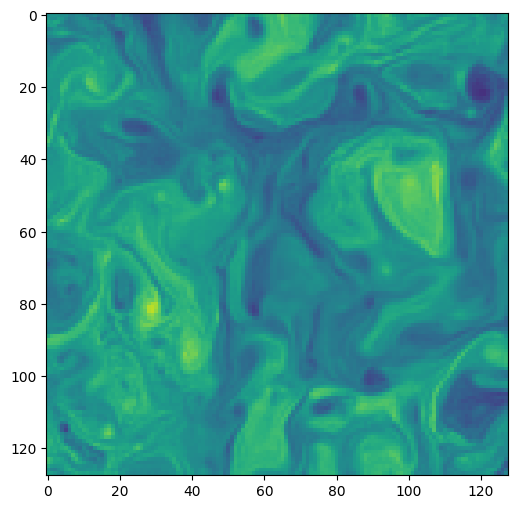

In [38]:

patch_size = 32
expand_ratio = 4
batch_size = 1

weight_grid_2d = gen_weight_grid(patch_size, expand_ratio)
print(weight_grid_2d.shape)

# PoU generation
output_size = patch_size * expand_ratio
latents = torch.randn([batch_size, 1, output_size, output_size], device=device)
samples = edm_sampler_pou(weight_grid_2d, net_32_patch, latents, num_steps=18)
print(samples.shape)

plt.figure(figsize=(6,6))
plt.imshow(samples[0,0,:,:].cpu().numpy(), cmap='viridis', vmin=-1.0, vmax=1.0)
# plt.axis('off')
plt.show()

In [56]:
from torch_utils import misc
import yaml
from pathlib import Path

In [73]:
with open("/home/zez0002/cond-diff-pou/configs/dataset_kwargs/sqg_patch_c0.yaml", "r") as f:
    dataset_kwargs = yaml.safe_load(f)

if dataset_kwargs['path'] is not None:
    if dataset_kwargs['data_path_full'] is None:
        dataset_kwargs['data_path_full'] = os.path.join(DATA_DIR, str(Path(dataset_kwargs['path'])))

with open("/home/zez0002/cond-diff-pou/configs/main.yaml", "r") as f:
    main = yaml.safe_load(f)
data_loader_kwargs = main["data_loader_kwargs"]

loss_kwargs = main["loss_kwargs"]

print(dataset_kwargs)
print(data_loader_kwargs)


{'name': 'sqg_patch_c0', 'path': 'SQG/SQG_v_0_patch_32_c_2/SQG_v_0_patch_32_c_2.zip', 'img_res_h': 32, 'img_res_w': 32, 'img_input_channels': 1, 'img_cond_channels': 0, 'class_name': 'training_cond.dataset.DatasetCond', 'xflip': True, 'yflip': True, 'cache': True, 'max_size': None, 'data_path_full': '/home/zez0002/cond-diff-pou/datasets/SQG/SQG_v_0_patch_32_c_2/SQG_v_0_patch_32_c_2.zip'}
{'pin_memory': True, 'num_workers': 1, 'prefetch_factor': 2}


In [74]:
batch_gpu = 256

dataset_obj = dnnlib.util.construct_class_by_name(**dataset_kwargs) # subclass of training.dataset.Dataset
dataset_sampler = misc.InfiniteSampler(dataset=dataset_obj, rank=dist.get_rank(), num_replicas=dist.get_world_size(), seed=0)
dataset_iterator = iter(torch.utils.data.DataLoader(dataset=dataset_obj, sampler=dataset_sampler, batch_size=batch_gpu, **data_loader_kwargs))

loss_fn = dnnlib.util.construct_class_by_name(**loss_kwargs) # training.loss.(VP|VE|EDM)Loss

Checking file shapes...
Max mismatches reached.
All files match expected shapes.


/home/zez0002/anaconda3/envs/edm/lib/python3.9/site-packages/torch/utils/data/sampler.py:68: UserWarning: `data_source` argument is not used and will be removed in 2.2.0.You may still have custom implementation that utilizes it.
  warnings.warn(


torch.Size([256, 1, 32, 32]) -0.7098039388656616 0.6627451181411743
torch.Size([256, 0, 32, 32])
loss: 0.07886231690645218
0.23131648


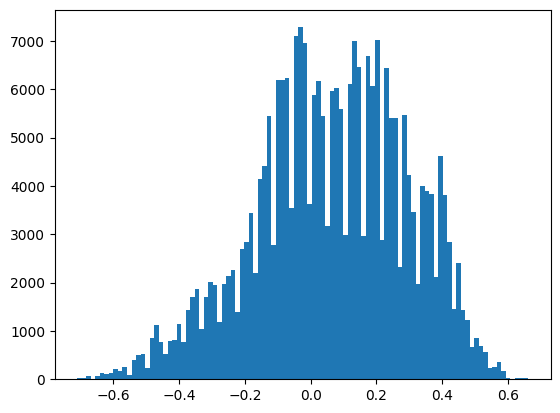

In [134]:
with torch.no_grad():
    images, conditions = next(dataset_iterator)
    images = images.to(device).to(torch.float32) # normalization is handled by the reprocessing
    conditions = conditions.to(device)
    print(images.shape, images.min().item(), images.max().item())
    print(conditions.shape)
    loss = loss_fn(net=model1, images=images, conditions=conditions)
    loss.sum()
    print('loss:', loss.mean().item())
    
    print(np.std(images.cpu().numpy()))
    plt.hist(images.cpu().numpy().flatten(), bins=100)
    plt.show()

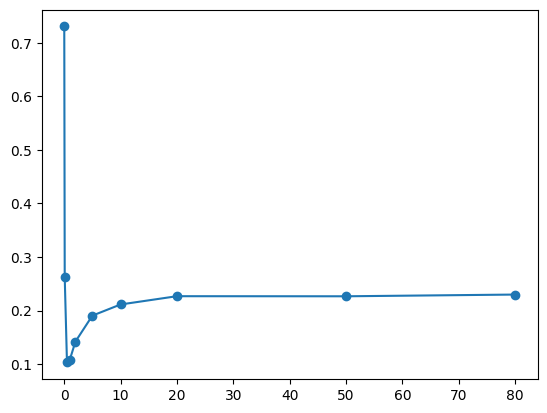

In [103]:
sigma_vec = torch.tensor([0.02, 0.1, 0.5, 1, 2, 5, 10, 20, 50, 80], device=device)
sigma_data = 0.5


loss_all = []
with torch.no_grad():
    for sig in sigma_vec:
        sigma = torch.ones([images.shape[0], 1, 1, 1], device=images.device) * sig
        weight = (sigma ** 2 + sigma_data ** 2) / (sigma * sigma_data) ** 2
        y = images
        n = torch.randn_like(y) * sigma

        D_yn = model2(y + n, sigma, conditions)
        loss = weight * ((D_yn - y) ** 2)
        loss_all.append(loss.mean().item())


plt.plot(sigma_vec.cpu(), loss_all, '-o')
plt.show()

In [104]:
loss_2 = loss_all

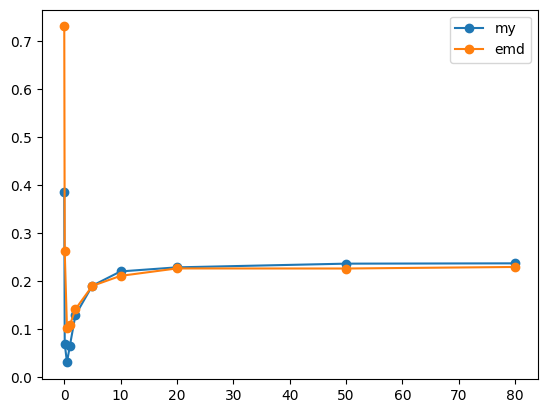

In [108]:
plt.plot(sigma_vec.cpu(), loss_1, '-o', label='my')
plt.plot(sigma_vec.cpu(), loss_2, '-o', label='emd')
# plt.xscale('log')
plt.legend()
plt.show()